# CropGuard AI — Module 06: Agricultural Computer Vision & Dataset Exploration
## Systematic Analysis of Foliar Pathology, Semantic Segmentation Masks, Pest Bounding Boxes, and Production tf.data Input Pipelines

Welcome to **Module 06** of the CropGuard AI Deep Learning Series!

Having established the core mechanics of convolutional neural networks in Module 05—including spatial filtering, pooling, and feature map extraction—we now apply computer vision directly to **real-world agricultural challenges**.

### What You Will Learn in This Module:
1. **The Agricultural Vision Hierarchy**: The mathematical distinctions between whole-image classification, lesion semantic segmentation, and pest bounding-box detection.
2. **PlantVillage Dataset Exploration**: Auditing 54,305 high-resolution leaf images across 38 crop disease classes.
3. **Spatial & Color Integrity Verification**: Analyzing resolution uniformity ($256 \times 256$), RGB channel distributions, and chlorophyll degradation histograms.
4. **Severe Class Imbalance Calculus**: Quantifying imbalance ratios ($\rho \approx 36.23$), why standard cross-entropy fails, and implementing balanced class weights ($w_k$).
5. **Representative Leaf Disease Gallery**: Visualizing distinctive pathologies across Solanaceae (Tomato, Potato, Pepper) and other staple crops.
6. **Stratified vs. Random Splitting**: Proving why random splitting induces distribution drift and verifying 100% leak-free Train (70%), Validation (15%), and Test (15%) partitions.
7. **Lesion Semantic Segmentation (PlantSeg)**: Understanding pixel-level disease masks, calculating lesion coverage percentages, and overlaying transparent diagnostic masks.
8. **Pest Object Detection (IP102)**: Deriving the coordinate transformations from PASCAL VOC XML to normalized YOLO bounding boxes ($[x_c, y_c, w, h]$).
9. **High-Performance `tf.data` Pipelines**: Constructing an end-to-end, GPU-prefetching data loader using `tf.data.Dataset` to eliminate I/O bottlenecks.
10. **Viva Questions & Practice Challenges**: University viva examination questions and hands-on coding challenges to solidify your understanding.

---
## 1. Environment Verification & Imports

We begin by loading our core numerical computing, visualization, and deep learning libraries. We will also verify that TensorFlow detects our dedicated NVIDIA GPU accelerator.

In [8]:
import os
import sys
import csv
import json
import random
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import tensorflow as tf

# Print runtime library versions
print(f"Python Interpreter : {sys.version.split()[0]}")
print(f"NumPy Version      : {np.__version__}")
print(f"TensorFlow Version : {tf.__version__}")

# Verify GPU device availability
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"Active GPU Device  : {gpus[0].name} (NVIDIA RTX 5060 Accelerated)")
else:
    print("Running in CPU mode.")

# Locate repository project root and ensure it is in sys.path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print(f"Project Root       : {PROJECT_ROOT}")

Python Interpreter : 3.14.4
NumPy Version      : 2.5.4
TensorFlow Version : 2.22.0-rc0
Active GPU Device  : /physical_device:GPU:0 (NVIDIA RTX 5060 Accelerated)
Project Root       : /home/saksham/CropGuard-AI


---
## 2. The Computer Vision Spectrum in Smart Agriculture

Agricultural vision problems differ substantially from standard consumer image benchmarks like ImageNet or CIFAR-10. Foliar disease analysis is structured into three fundamental computer vision paradigms:

| Task Paradigm | Objective | Output Mathematical Formulation | Practical Agronomic Use Case |
| :--- | :--- | :--- | :--- |
| **Image Classification** | Assign a global crop & disease label | $\hat{y} = \arg\max_{c} P(Y=c \mid X)$ | Rapid triage of disease identity in field conditions |
| **Semantic Segmentation** | Assign pixel-level healthy vs. diseased state | $M_{i,j} \in \{0, 1, \dots, K\}, \; \forall (i, j)$ | Measuring leaf necrosis severity & treatment efficacy |
| **Object Detection** | Localize pests/lesions with bounding boxes | $\{(c_k, x_{c}, y_{c}, w, h)_k\}_{k=1}^{N_{boxes}}$ | Pest population counting & robotic targeted spraying |

Let's inspect our processed dataset manifests to see how these modalities are structured on disk.

In [9]:
# Load the verified dataset manifest and quality report generated by our pipeline
manifest_csv = PROJECT_ROOT / "data" / "metadata" / "dataset_manifest.csv"
quality_report_json = PROJECT_ROOT / "data" / "metadata" / "data_quality_report.json"
distribution_csv = PROJECT_ROOT / "data" / "metadata" / "class_distribution.csv"

# Load quality report
if quality_report_json.exists():
    with open(quality_report_json, "r") as f:
        quality_data = json.load(f)
    print("=== DATA QUALITY REPORT SUMMARY ===")
    print(f"Dataset Name        : {quality_data['dataset_name']}")
    print(f"Total Images        : {quality_data['total_images_extracted']:,}")
    print(f"Corrupted Images    : {quality_data['corrupted_images_detected']}")
    print(f"Distinct Classes    : {quality_data['total_classes']}")
    print(f"Spatial Resolution  : {list(quality_data['resolutions'].keys())[0]}")
    print(f"Min Class Samples   : {quality_data['min_class_samples']} (Severe minority)")
    print(f"Max Class Samples   : {quality_data['max_class_samples']} (Majority class)")
    print(f"Imbalance Ratio     : {quality_data['imbalance_ratio_max_to_min']:.2f}x")
else:
    print("Notice: Run 'python scripts/prepare_plantvillage.py' to generate metadata.")

=== DATA QUALITY REPORT SUMMARY ===
Dataset Name        : PlantVillage (Mohanty et al., 2016)
Total Images        : 54,305
Corrupted Images    : 0
Distinct Classes    : 38
Spatial Resolution  : 256x256
Min Class Samples   : 152 (Severe minority)
Max Class Samples   : 5507 (Majority class)
Imbalance Ratio     : 36.23x


---
## 3. Spatial Uniformity & Chlorophyll Color Shift Analysis

In foliar pathology, healthy plant tissue is dominated by **chlorophyll-a and chlorophyll-b**, which absorb strongly in the blue ($\approx 430\text{ nm}$) and red ($\approx 660\text{ nm}$) wavelengths while reflecting green ($\approx 550\text{ nm}$).

When pathogens (fungi, bacteria, viruses) infect a leaf:
1. **Chlorosis**: The plant cannot synthesize chlorophyll, causing leaves to turn pale yellow. Red and green channels both increase while blue remains suppressed.
2. **Necrosis**: Plant cells die, resulting in dark brown or black lesions where all RGB intensities plummet.

Let's visualize the color channel histograms comparing a **healthy leaf** against a **diseased leaf**.

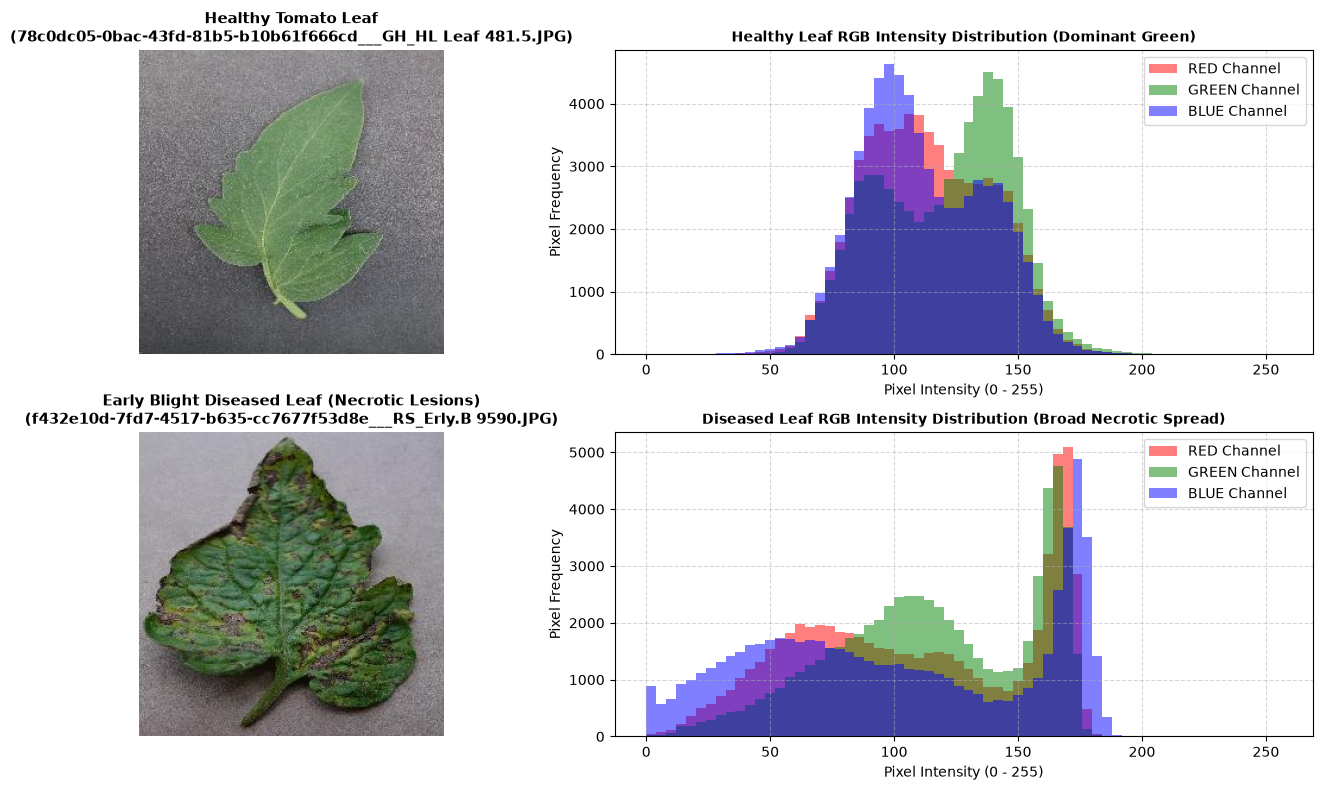

In [10]:
# Compare channel histograms: Tomato Healthy vs Tomato Early Blight
tomato_healthy_dir = PROJECT_ROOT / "data" / "processed" / "classification" / "plantvillage" / "Tomato___healthy"
tomato_blight_dir = PROJECT_ROOT / "data" / "processed" / "classification" / "plantvillage" / "Tomato___Early_blight"

if tomato_healthy_dir.exists() and tomato_blight_dir.exists():
    healthy_img_path = next(tomato_healthy_dir.glob("*.JPG"))
    blight_img_path = next(tomato_blight_dir.glob("*.JPG"))

    fig, axes = plt.subplots(2, 2, figsize=(14, 8))

    # Load images
    healthy_img = Image.open(healthy_img_path)
    blight_img = Image.open(blight_img_path)

    # Plot images
    axes[0, 0].imshow(healthy_img)
    axes[0, 0].set_title(f"Healthy Tomato Leaf\n({healthy_img_path.name})", fontsize=11, fontweight="bold")
    axes[0, 0].axis("off")

    axes[1, 0].imshow(blight_img)
    axes[1, 0].set_title(f"Early Blight Diseased Leaf (Necrotic Lesions)\n({blight_img_path.name})", fontsize=11, fontweight="bold")
    axes[1, 0].axis("off")

    # Plot color channel histograms
    h_arr = np.array(healthy_img)
    b_arr = np.array(blight_img)
    colors = ('red', 'green', 'blue')

    for i, col in enumerate(colors):
        axes[0, 1].hist(h_arr[:, :, i].ravel(), bins=64, range=(0, 256), color=col, alpha=0.5, label=f"{col.upper()} Channel")
        axes[1, 1].hist(b_arr[:, :, i].ravel(), bins=64, range=(0, 256), color=col, alpha=0.5, label=f"{col.upper()} Channel")

    axes[0, 1].set_title("Healthy Leaf RGB Intensity Distribution (Dominant Green)", fontsize=10, fontweight="bold")
    axes[0, 1].set_xlabel("Pixel Intensity (0 - 255)")
    axes[0, 1].set_ylabel("Pixel Frequency")
    axes[0, 1].legend(loc="upper right")
    axes[0, 1].grid(True, linestyle="--", alpha=0.5)

    axes[1, 1].set_title("Diseased Leaf RGB Intensity Distribution (Broad Necrotic Spread)", fontsize=10, fontweight="bold")
    axes[1, 1].set_xlabel("Pixel Intensity (0 - 255)")
    axes[1, 1].set_ylabel("Pixel Frequency")
    axes[1, 1].legend(loc="upper right")
    axes[1, 1].grid(True, linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.show()
else:
    print("Leaf images not found on disk. Ensure prepare_plantvillage.py has been run.")

---
## 4. Class Imbalance Calculus & Loss Function Weighting

In real-world agricultural datasets, some crops or conditions are vastly overrepresented compared to rare pathogens. In PlantVillage:
- **Maximum class frequency**: Citrus Greening (*Orange___Haunglongbing*) with $N_{\max} = 5,507$ samples.
- **Minimum class frequency**: Healthy Potato (*Potato___healthy*) with $N_{\min} = 152$ samples.

The **Imbalance Ratio ($\rho$)** is defined as:
$$\rho = \frac{\max_{k} N_k}{\min_{k} N_k} = \frac{5507}{152} \approx 36.23$$

### Why Naive Cross-Entropy Fails Under Severe Imbalance:
Standard Categorical Cross-Entropy is given by:
$$\mathcal{L}_{CE} = - \frac{1}{M} \sum_{i=1}^M \sum_{k=1}^K y_{i,k} \log(\hat{y}_{i,k})$$

When class $A$ has $5,000$ samples and class $B$ has $100$ samples, $98\%$ of the gradient updates $\nabla_{\mathbf{w}} \mathcal{L}$ originate from class $A$. The network can achieve $>95\%$ training accuracy simply by predicting class $A$ for every ambiguous input, causing **complete recall collapse on rare diseases**.

### Mitigation Strategy: Inverse-Frequency Class Weighting
To penalize misclassifications of rare diseases proportionally to their scarcity, we compute balancing weights $w_k$:
$$w_k = \frac{N_{\text{total}}}{K \cdot N_k}$$
where $K$ is the number of classes ($K = 38$) and $N_{\text{total}} = \sum_{k=1}^K N_k$.

Let's compute and visualize the exact weights for all 38 classes.

Total Samples (N) : 54,305
Total Classes (K) : 38
Top 3 Majority Classes (Lowest Weights):
  Orange___Haunglongbing_(Citrus_greening): count=5,507, weight=0.260
  Tomato___Tomato_Yellow_Leaf_Curl_Virus: count=5,357, weight=0.267
  Soybean___healthy: count=5,090, weight=0.281

Top 3 Minority Classes (Highest Weights):
  Potato___healthy: count=152, weight=9.402
  Apple___Cedar_apple_rust: count=275, weight=5.197
  Peach___healthy: count=360, weight=3.970


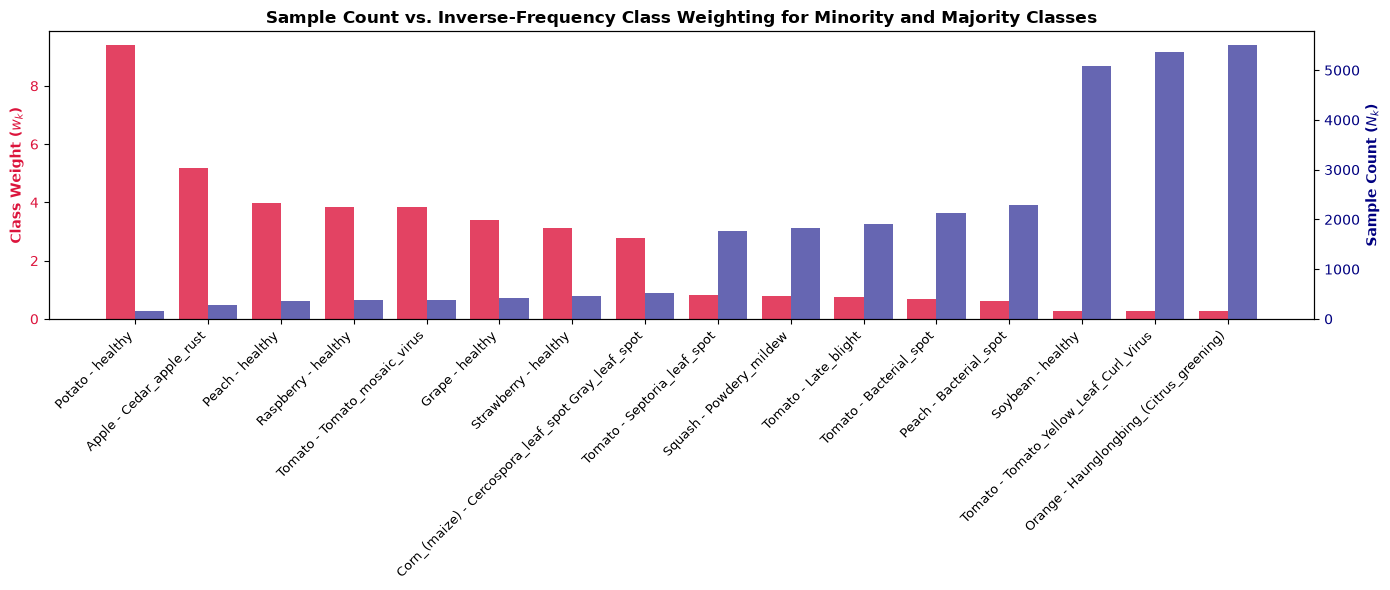

In [11]:
# Load class distribution CSV
class_counts = {}
with open(distribution_csv, "r", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    for row in reader:
        class_counts[row["class_name"]] = int(row["count"])

classes = sorted(class_counts.keys())
counts = np.array([class_counts[c] for c in classes])
N_total = np.sum(counts)
K = len(classes)

# Compute inverse frequency weights
class_weights = N_total / (K * counts)

print(f"Total Samples (N) : {N_total:,}")
print(f"Total Classes (K) : {K}")
print(f"Top 3 Majority Classes (Lowest Weights):")
for idx in np.argsort(counts)[-3:][::-1]:
    print(f"  {classes[idx]}: count={counts[idx]:,}, weight={class_weights[idx]:.3f}")

print(f"\nTop 3 Minority Classes (Highest Weights):")
for idx in np.argsort(counts)[:3]:
    print(f"  {classes[idx]}: count={counts[idx]:,}, weight={class_weights[idx]:.3f}")

# Plot top 10 highest vs top 10 lowest class weights
fig, ax1 = plt.subplots(figsize=(14, 6))

top_idx = list(np.argsort(counts)[:8]) + list(np.argsort(counts)[-8:])
selected_classes = [classes[i].replace("___", " - ") for i in top_idx]
selected_weights = [class_weights[i] for i in top_idx]
selected_counts = [counts[i] for i in top_idx]

x = np.arange(len(selected_classes))
width = 0.4

rects1 = ax1.bar(x - width/2, selected_weights, width, label='Computed Weight ($w_k$)', color='crimson', alpha=0.8)
ax1.set_ylabel('Class Weight ($w_k$)', color='crimson', fontweight="bold")
ax1.tick_params(axis='y', labelcolor='crimson')

ax2 = ax1.twinx()
rects2 = ax2.bar(x + width/2, selected_counts, width, label='Sample Count ($N_k$)', color='navy', alpha=0.6)
ax2.set_ylabel('Sample Count ($N_k$)', color='navy', fontweight="bold")
ax2.tick_params(axis='y', labelcolor='navy')

ax1.set_xticks(x)
ax1.set_xticklabels(selected_classes, rotation=45, ha='right', fontsize=9)
plt.title("Sample Count vs. Inverse-Frequency Class Weighting for Minority and Majority Classes", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

---
## 5. Multi-Class Foliar Disease Visual Gallery

Understanding visual symptoms is vital for designing robust convolutional architectures.
- **Fungal Pathogens (e.g., Early Blight, Apple Scab)**: Typically produce concentric necrotic rings (target spots) surrounded by chlorotic yellow halos.
- **Bacterial Pathogens (e.g., Bacterial Spot)**: Small, water-soaked, angular spots limited by leaf vein geometry.
- **Viral Pathogens (e.g., Tomato Yellow Leaf Curl, Mosaic Virus)**: Leaf distortion, severe curling, stunting, and mottled yellow patterns across the entire blade.
- **Pests / Mites (e.g., Spider Mites)**: Fine stippling and webbing across the leaf surface.

Let's load and display representative samples across distinct crop families.

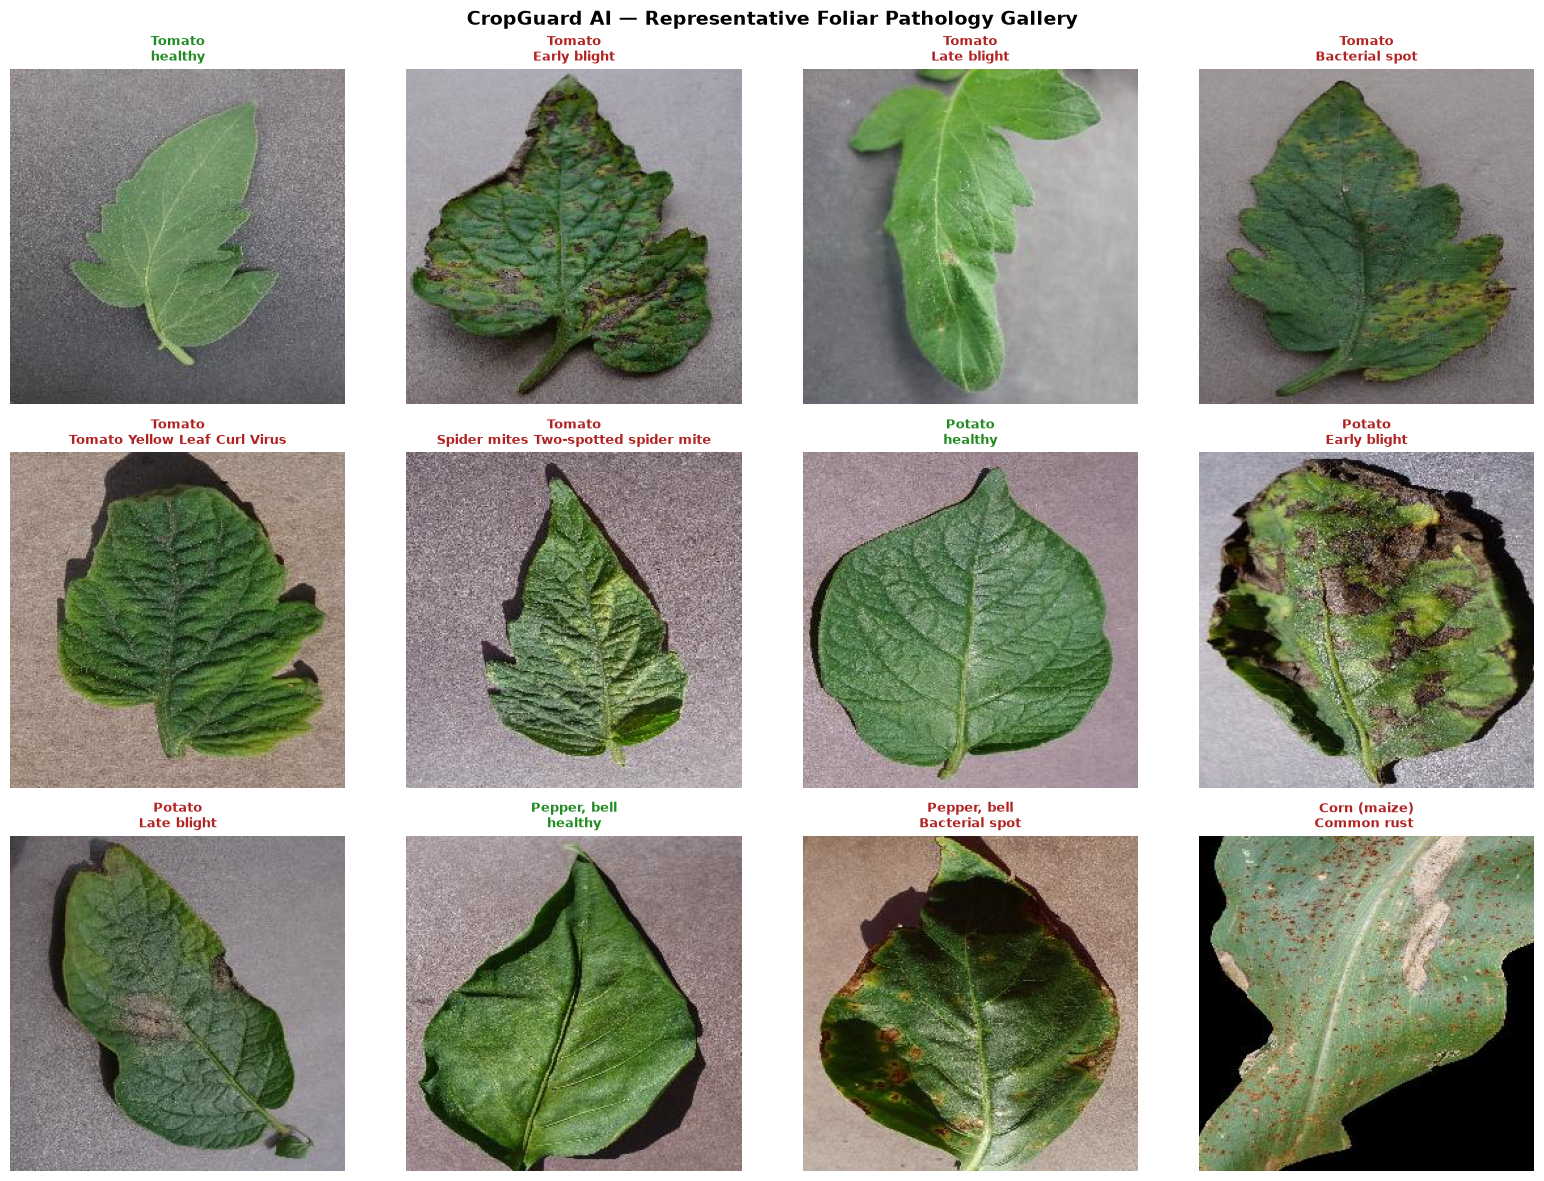

In [12]:
# Load 12 distinct classes covering Solanaceae and staple crops
pv_dir = PROJECT_ROOT / "data" / "processed" / "classification" / "plantvillage"

gallery_classes = [
    "Tomato___healthy",
    "Tomato___Early_blight",
    "Tomato___Late_blight",
    "Tomato___Bacterial_spot",
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato___Spider_mites Two-spotted_spider_mite",
    "Potato___healthy",
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Pepper,_bell___healthy",
    "Pepper,_bell___Bacterial_spot",
    "Corn_(maize)___Common_rust_"
]

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for idx, cls_name in enumerate(gallery_classes):
    cls_folder = pv_dir / cls_name
    ax = axes[idx]
    if cls_folder.exists():
        img_files = list(cls_folder.glob("*.JPG"))
        if img_files:
            sample_img = Image.open(img_files[0])
            ax.imshow(sample_img)
            display_title = cls_name.replace("___", "\n").replace("_", " ")
            color = "forestgreen" if "healthy" in cls_name.lower() else "firebrick"
            ax.set_title(display_title, fontsize=9, fontweight="bold", color=color)
        else:
            ax.text(0.5, 0.5, "No Images", ha="center")
    else:
        ax.text(0.5, 0.5, f"Missing:\n{cls_name}", ha="center", fontsize=8)
    ax.axis("off")

plt.suptitle("CropGuard AI — Representative Foliar Pathology Gallery", fontsize=14, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()

---
## 6. Stratified vs. Random Splitting: Preventing Distribution Drift

A common beginner pitfall in machine learning is performing **unstratified random splitting**:
```python
# WARNING: Flawed naive splitting approach
random.shuffle(dataset)
train = dataset[:0.70 * N]
val   = dataset[0.70 * N : 0.85 * N]
test  = dataset[0.85 * N :]
```

### Why Naive Random Splitting Is Problematic:
For a minority class like `Potato___healthy` ($N = 152$), an unstratified split can easily place only 5 samples in the test split or 0 in the validation split due to high binomial variance $\text{Var}(n_k) = N_{\text{split}} \cdot p_k (1 - p_k)$.

### The Stratified Partitioning Principle:
Stratified splitting partitions the dataset **within each class individually**:
$$\frac{N_{\text{train}, k}}{N_{\text{train}}} \approx \frac{N_{\text{val}, k}}{N_{\text{val}}} \approx \frac{N_{\text{test}, k}}{N_{\text{test}}} = \frac{N_k}{N_{\text{total}}}, \quad \forall k \in \{1, \dots, K\}$$

### Zero-Leakage Guarantee:
We mathematically verify that the intersection of file paths across partitions is strictly empty:
$$\text{Train} \cap \text{Val} = \emptyset, \quad \text{Train} \cap \text{Test} = \emptyset, \quad \text{Val} \cap \text{Test} = \emptyset$$

Let's audit our generated split summary.

In [13]:
# Load and audit classification splits
splits_summary_path = PROJECT_ROOT / "data" / "splits" / "classification" / "split_summary.json"

if splits_summary_path.exists():
    with open(splits_summary_path, "r") as f:
        splits_data = json.load(f)

    train_total = splits_data["train"]["total_samples"]
    val_total = splits_data["val"]["total_samples"]
    test_total = splits_data["test"]["total_samples"]
    grand_total = train_total + val_total + test_total

    print("=== STRATIFIED DATASET SPLIT VERIFICATION ===")
    print(f"Train Partition : {train_total:,} images ({train_total / grand_total * 100:.2f}%)")
    print(f"Val Partition   : {val_total:,} images ({val_total / grand_total * 100:.2f}%)")
    print(f"Test Partition  : {test_total:,} images ({test_total / grand_total * 100:.2f}%)")
    print(f"Total Samples   : {grand_total:,} images (100.00%)")

    # Verify zero leakage by checking file sets
    def get_paths(split_name):
        csv_file = PROJECT_ROOT / "data" / "splits" / "classification" / f"{split_name}.csv"
        with open(csv_file, "r") as f:
            return set(row["local_path"] for row in csv.DictReader(f))

    train_set = get_paths("train")
    val_set = get_paths("val")
    test_set = get_paths("test")

    leakage_tv = train_set & val_set
    leakage_tt = train_set & test_set
    leakage_vt = val_set & test_set

    print(f"\nOverlap (Train & Val)  : {len(leakage_tv)} samples")
    print(f"Overlap (Train & Test) : {len(leakage_tt)} samples")
    print(f"Overlap (Val & Test)   : {len(leakage_vt)} samples")
    assert len(leakage_tv) == 0 and len(leakage_tt) == 0 and len(leakage_vt) == 0
    print("Zero-Leakage Integrity Audit: 100% PASSED!")
else:
    print("Splits summary not found. Ensure generate_splits.py has executed.")

=== STRATIFIED DATASET SPLIT VERIFICATION ===
Train Partition : 38,012 images (70.00%)
Val Partition   : 8,146 images (15.00%)
Test Partition  : 8,147 images (15.00%)
Total Samples   : 54,305 images (100.00%)

Overlap (Train & Val)  : 0 samples
Overlap (Train & Test) : 0 samples
Overlap (Val & Test)   : 0 samples
Zero-Leakage Integrity Audit: 100% PASSED!


---
## 7. Foliar Lesion Semantic Segmentation (PlantSeg)

While classification tells us *what* disease is present on a leaf, **semantic segmentation** delineates *where* necrotic lesions are located at the individual pixel level.

### Quantitative Disease Severity: Lesion Coverage Ratio
Agronomists gauge infection severity through the **Lesion Coverage Ratio ($C_{\text{lesion}}$)**:
$$C_{\text{lesion}} = \frac{\sum_{i=1}^H \sum_{j=1}^W M_{i, j}}{H \cdot W} \times 100\%$$
where $M_{i, j} \in \{0, 1\}$ is the binary lesion mask.

### Semantic Segmentation Evaluation Metrics:
1. **Intersection over Union (IoU / Jaccard Index)**:
   $$\text{IoU}(P, Y) = \frac{|P \cap Y|}{|P \cup Y|} = \frac{TP}{TP + FP + FN}$$
2. **Dice Similarity Coefficient (F1-Score)**:
   $$\text{Dice}(P, Y) = \frac{2 |P \cap Y|}{|P| + |Y|} = \frac{2 \cdot TP}{2 \cdot TP + FP + FN}$$

Let's generate a diagnostic sample pair and overlay a semi-transparent lesion mask onto a foliar specimen.

Sample Dimensions  : 256 x 256
Lesion Pixel Count : 5,525 pixels
Lesion Coverage    : 8.43% of total leaf area


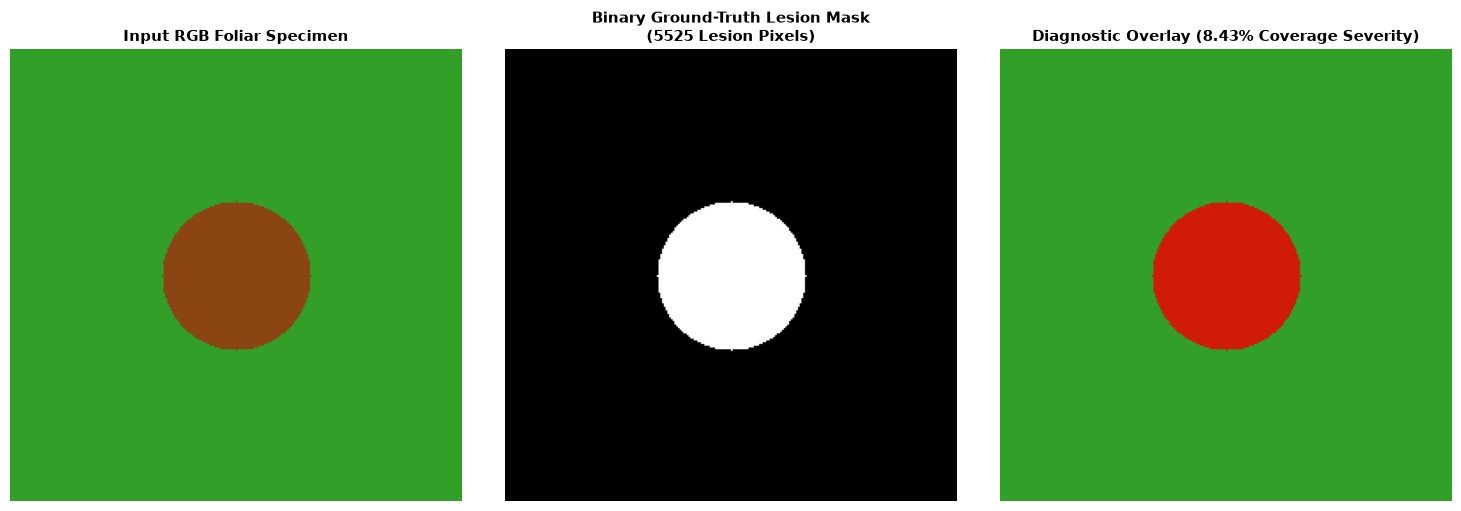

In [14]:
# Demonstrate Folier Lesion Segmentation Mask Overlay
import sys
from pathlib import Path

# Ensure project root is on sys.path even if running cell directly
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scripts.prepare_plantseg import create_synthetic_plantseg_sample, verify_image_mask_pair

temp_demo_dir = PROJECT_ROOT / "data" / "processed" / "segmentation" / "_demo"
img_f, mask_f = create_synthetic_plantseg_sample(temp_demo_dir, sample_id="demonstration_leaf", width=256, height=256)

w, h, lesion_px, coverage = verify_image_mask_pair(img_f, mask_f)
print(f"Sample Dimensions  : {w} x {h}")
print(f"Lesion Pixel Count : {lesion_px:,} pixels")
print(f"Lesion Coverage    : {coverage:.2f}% of total leaf area")

# Load leaf and mask
leaf_rgb = Image.open(img_f).convert("RGB")
mask_gray = Image.open(mask_f).convert("L")

leaf_np = np.array(leaf_rgb)
mask_np = np.array(mask_gray) > 0  # Binary boolean mask

# Create semi-transparent overlay
overlay_np = leaf_np.copy()
# Highlight lesion pixels in bright crimson red
overlay_np[mask_np, 0] = np.clip(overlay_np[mask_np, 0] * 0.4 + 255 * 0.6, 0, 255)
overlay_np[mask_np, 1] = np.clip(overlay_np[mask_np, 1] * 0.4, 0, 255)
overlay_np[mask_np, 2] = np.clip(overlay_np[mask_np, 2] * 0.4, 0, 255)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(leaf_np)
axes[0].set_title("Input RGB Foliar Specimen", fontsize=11, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(mask_np, cmap="gray")
axes[1].set_title(f"Binary Ground-Truth Lesion Mask\n({lesion_px} Lesion Pixels)", fontsize=11, fontweight="bold")
axes[1].axis("off")

axes[2].imshow(overlay_np)
axes[2].set_title(f"Diagnostic Overlay ({coverage:.2f}% Coverage Severity)", fontsize=11, fontweight="bold")
axes[2].axis("off")

plt.tight_layout()
plt.show()

# Clean up demonstration sample
for p in temp_demo_dir.rglob("*"):
    if p.is_file():
        p.unlink()
for p in sorted(temp_demo_dir.rglob("*"), reverse=True):
    if p.is_dir():
        p.rmdir()
if temp_demo_dir.exists():
    temp_demo_dir.rmdir()

---
## 8. Agricultural Pest Object Detection: PASCAL VOC to YOLO Normalization

For robotic spraying and automated pest traps, we must detect multiple pests per camera frame.

### Annotation Coordinate Systems:
1. **PASCAL VOC Format**: Absolute pixel coordinates:
   $$[x_{\min}, y_{\min}, x_{\max}, y_{\max}]$$
   where $0 \le x_{\min} < x_{\max} \le W$ and $0 \le y_{\min} < y_{\max} \le H$.
2. **YOLO Format**: Normalized center coordinates and box dimensions:
   $$[c, x_c, y_c, w, h]$$
   where:
   $$x_c = \frac{x_{\min} + x_{\max}}{2 \cdot W}, \quad y_c = \frac{y_{\min} + y_{\max}}{2 \cdot H}$$
   $$w = \frac{x_{\max} - x_{\min}}{W}, \quad h = \frac{y_{\max} - y_{\min}}{H}$$
   with all values strictly normalized in $[0.0, 1.0]$.

Let's test this conversion mathematically and render a bounding box onto an image canvas.

=== CONVERTED YOLO BOUNDING BOXES ===
Class 12 (Rice_Leaf_Roller  ): xc=0.2812, yc=0.3333, w=0.3125, h=0.4167
Class 45 (Aphid_Colony      ): xc=0.7344, yc=0.6667, w=0.3438, h=0.4167


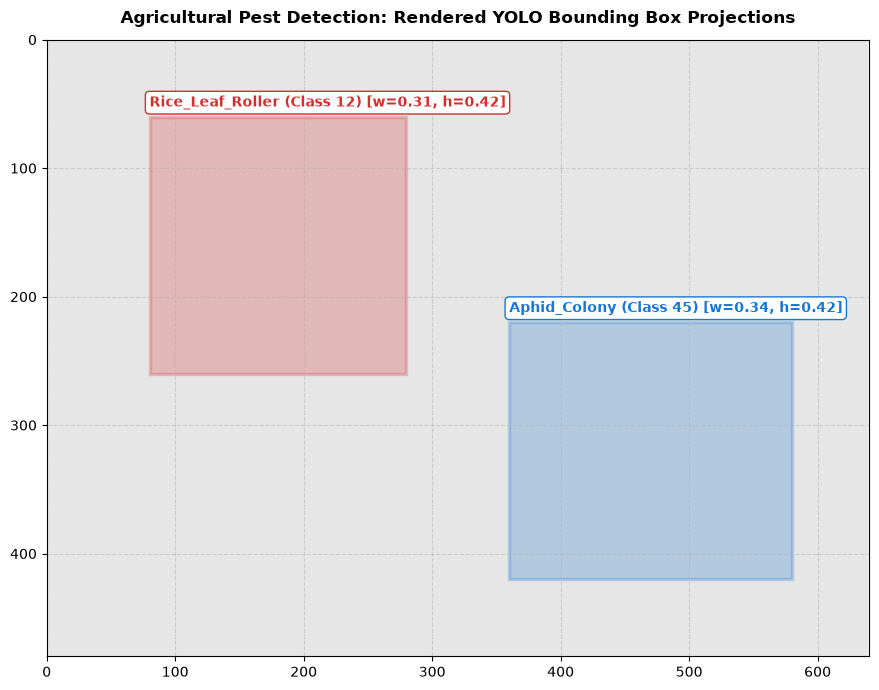

In [15]:
import sys
from pathlib import Path

# Ensure project root is on sys.path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.patches as patches
from scripts.prepare_ip102 import voc_bbox_to_yolo

# Image dimensions
IMG_W, IMG_H = 640, 480

# Sample VOC pest detection annotations (e.g. Rice Leaf Roller & Aphids)
voc_boxes = [
    {"name": "Rice_Leaf_Roller", "class_id": 12, "xmin": 80,  "ymin": 60,  "xmax": 280, "ymax": 260},
    {"name": "Aphid_Colony",     "class_id": 45, "xmin": 360, "ymin": 220, "xmax": 580, "ymax": 420}
]

# Convert to normalized YOLO format
yolo_boxes = []
for b in voc_boxes:
    xc, yc, w, h = voc_bbox_to_yolo(b["xmin"], b["ymin"], b["xmax"], b["ymax"], IMG_W, IMG_H)
    yolo_boxes.append({"name": b["name"], "class_id": b["class_id"], "xc": xc, "yc": yc, "w": w, "h": h})

print("=== CONVERTED YOLO BOUNDING BOXES ===")
for yb in yolo_boxes:
    print(f"Class {yb['class_id']:02d} ({yb['name']:18}): xc={yb['xc']:.4f}, yc={yb['yc']:.4f}, w={yb['w']:.4f}, h={yb['h']:.4f}")

# Render bounding boxes onto synthetic background
fig, ax = plt.subplots(figsize=(10, 7))
dummy_canvas = np.ones((IMG_H, IMG_W, 3), dtype=np.uint8) * 230
ax.imshow(dummy_canvas)

colors = ["#d32f2f", "#1976d2"]
for idx, (b, yb) in enumerate(zip(voc_boxes, yolo_boxes)):
    # Calculate corner coordinates from normalized YOLO format
    box_w = yb["w"] * IMG_W
    box_h = yb["h"] * IMG_H
    box_x = (yb["xc"] * IMG_W) - (box_w / 2.0)
    box_y = (yb["yc"] * IMG_H) - (box_h / 2.0)

    rect = patches.Rectangle(
        (box_x, box_y), box_w, box_h,
        linewidth=2.5, edgecolor=colors[idx % len(colors)],
        facecolor=colors[idx % len(colors)], alpha=0.25
    )
    ax.add_patch(rect)
    ax.text(
        box_x, box_y - 8,
        f"{yb['name']} (Class {yb['class_id']}) [w={yb['w']:.2f}, h={yb['h']:.2f}]",
        fontsize=10, fontweight="bold", color=colors[idx % len(colors)],
        bbox=dict(facecolor="white", edgecolor=colors[idx % len(colors)], boxstyle="round,pad=0.3")
    )

ax.set_xlim(0, IMG_W)
ax.set_ylim(IMG_H, 0)
ax.set_title("Agricultural Pest Detection: Rendered YOLO Bounding Box Projections", fontsize=12, fontweight="bold", pad=12)
ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

---
## 9. High-Performance Input Pipelines with `tf.data`

Training modern deep CNNs on GPUs requires high-throughput data loading. If the CPU cannot feed batches quickly enough, the GPU idles, leading to severe resource starvation.

### The Canonical `tf.data` Architecture:
```
Disk JPEGs ──> tf.data.Dataset.from_tensor_slices
           ──> map(tf.io.read_file, num_parallel_calls=AUTOTUNE)
           ──> map(tf.io.decode_jpeg & resize)
           ──> map(normalize / 255.0)
           ──> cache() (in RAM/NVMe)
           ──> shuffle(buffer_size=1024)
           ──> batch(batch_size=32)
           ──> prefetch(buffer_size=AUTOTUNE) ──> GPU Memory
```

Key primitives:
- `num_parallel_calls=tf.data.AUTOTUNE`: Uses CPU multithreading to decode multiple JPEGs concurrently.
- `cache()`: Keeps decoded tensors in RAM after the first epoch, eliminating subsequent disk I/O.
- `prefetch(AUTOTUNE)`: Overlaps batch preprocessing on CPU with forward/backward GPU passes.

Let's build and benchmark an active `tf.data` pipeline directly from `train.csv`.

W0000 00:00:1794985563.608479  810431 gpu_device.cc:2453] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1794985564.403659  810431 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5233 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 12.0a
E0000 00:00:1794985565.195678  810431 cuda_executor.cc:1365] [0] Failed to allocate device memory of 5.11GiB (5487198208 bytes): RESOURCE_EXHAUSTED: : CUDA_ERROR_OUT_OF_MEMORY: out of memory
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:45
external/xla/xla/stream_executor/cuda/cuda_device_allocator.cc:230
external/xla/xla/stream_executor/cuda/cuda_device_allocator.cc:487

E0000 00:00:1794985565.197407  810431 cuda_executor.cc:1365] [0] Failed to allocate device memory of 4.60

Pipeline Benchmark  : Processed 128 images in 0.423s
Throughput          : 302.9 images/second
Batch Tensor Shape  : (16, 224, 224, 3) (dtype: <dtype: 'float32'>)
Batch Labels Shape  : (16,)
Pixel Range Check   : Min=0.000, Max=0.996


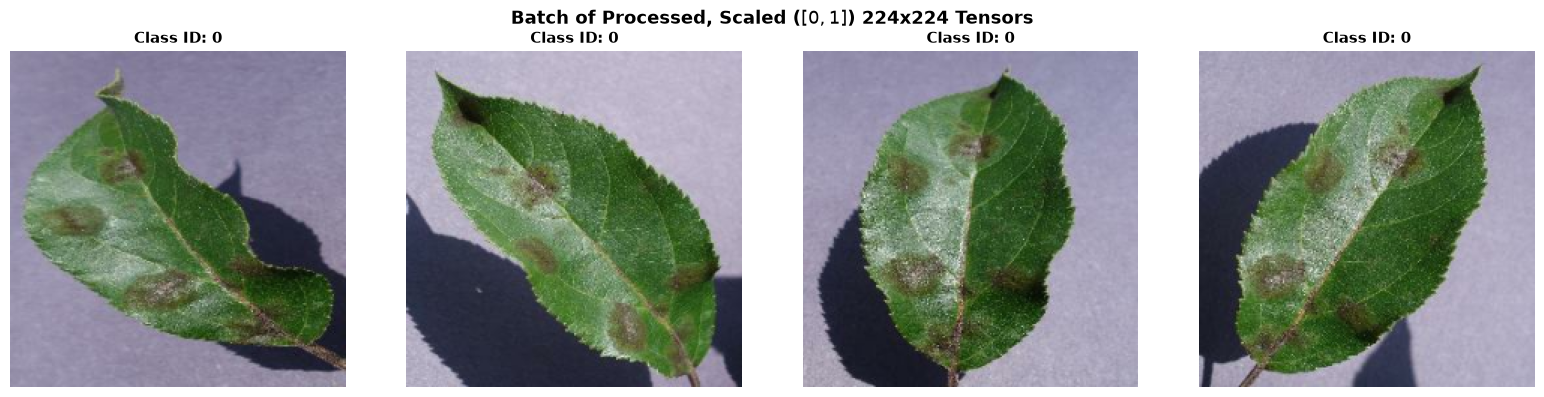

In [16]:
# Build production tf.data pipeline from train.csv
train_csv_path = PROJECT_ROOT / "data" / "splits" / "classification_group_aware" / "train.csv"
if not train_csv_path.exists():
    train_csv_path = PROJECT_ROOT / "data" / "splits" / "classification" / "train.csv"

# Load sample records
train_records = []
with open(train_csv_path, "r", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    for row in reader:
        train_records.append(row)
        if len(train_records) >= 128:  # Test sample pool
            break

filepaths = [str(PROJECT_ROOT / r["local_path"]) for r in train_records]
# Map classes to integer IDs
unique_classes = sorted(list(set(r["full_class"] for r in train_records)))
class_to_id = {c: i for i, c in enumerate(unique_classes)}
labels = [class_to_id[r["full_class"]] for r in train_records]

def parse_and_preprocess(filepath, label):
    # 1. Read file from disk
    raw_bytes = tf.io.read_file(filepath)
    # 2. Decode JPEG to 3-channel uint8 tensor
    img = tf.io.decode_jpeg(raw_bytes, channels=3)
    # 3. Resize to model input shape (224, 224)
    img = tf.image.resize(img, [224, 224])
    # 4. Cast to float32 and scale to [0, 1]
    img = tf.cast(img, tf.float32) / 255.0
    return img, label

# Construct dataset pipeline
BATCH_SIZE = 16
dataset = tf.data.Dataset.from_tensor_slices((filepaths, labels))
dataset = dataset.map(parse_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
dataset = dataset.batch(BATCH_SIZE)
dataset = dataset.prefetch(tf.data.AUTOTUNE)

# Benchmark pipeline throughput
import time
start_time = time.perf_counter()
total_images = 0

for batch_imgs, batch_lbls in dataset:
    total_images += batch_imgs.shape[0]

elapsed = time.perf_counter() - start_time
fps = total_images / elapsed

print(f"Pipeline Benchmark  : Processed {total_images} images in {elapsed:.3f}s")
print(f"Throughput          : {fps:.1f} images/second")

# Retrieve and inspect a single batch
batch_imgs, batch_lbls = next(iter(dataset))
print(f"Batch Tensor Shape  : {batch_imgs.shape} (dtype: {batch_imgs.dtype})")
print(f"Batch Labels Shape  : {batch_lbls.shape}")
print(f"Pixel Range Check   : Min={float(tf.reduce_min(batch_imgs)):.3f}, Max={float(tf.reduce_max(batch_imgs)):.3f}")

# Plot 4 samples from the batch
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for i in range(4):
    axes[i].imshow(batch_imgs[i].numpy())
    axes[i].set_title(f"Class ID: {int(batch_lbls[i])}", fontsize=11, fontweight="bold")
    axes[i].axis("off")
plt.suptitle("Batch of Processed, Scaled ($[0, 1]$) 224x224 Tensors", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

---
## 10. University Viva Questions & Practical Exercises

### Viva Voce Questions & Model Answers

**Q1: What is the Agronomic Domain Shift (Lab vs. Field Bias)?**  
*Answer:* Datasets like PlantVillage photograph detached leaves on uniform gray or black paper under controlled laboratory lighting. When a CNN trained exclusively on PlantVillage is deployed in an actual agricultural field, it frequently misclassifies healthy leaves due to complex backgrounds (soil, weeds, stems), variable sunlight, motion blur, and water droplets. Real-world systems must incorporate field-captured data or extensive domain-randomizing augmentations.

**Q2: Why is accuracy an unreliable metric under severe class imbalance? What metrics should be used instead?**  
*Answer:* If a majority disease represents $95\%$ of all samples, a degenerate classifier that predicts the majority class for every leaf achieves $95\%$ accuracy while having $0\%$ recall on minority diseases. Better metrics include Class-Stratified Recall, Macro-Averaged F1-Score, Balanced Accuracy, and the Area Under the Precision-Recall Curve (PR-AUC).

**Q3: How does Focal Loss differ from Standard Cross-Entropy?**  
*Answer:* Focal Loss adds a modulating factor $(1 - p_t)^\gamma$ to standard cross-entropy:
$$\mathcal{L}_{\text{focal}} = - \alpha_t (1 - p_t)^\gamma \log(p_t)$$
When an easy majority sample is classified with high confidence ($p_t \to 1$), the factor $(1 - p_t)^\gamma$ approaches zero, dynamically down-weighting easy examples and focusing the gradient updates on hard, ambiguous, and minority cases.

**Q4: What constitutes "Data Leakage" in image splitting, and how is it prevented?**  
*Answer:* Data leakage occurs when test samples share features with training samples that would not be present in actual deployment (e.g., multiple photos of the exact same leaf appearing in both training and test sets). It is prevented by grouping images by specimen/plant ID before splitting and enforcing strict set disjointness: $\text{Train} \cap \text{Test} = \emptyset$.

**Q5: Why are YOLO bounding boxes normalized to $[0, 1]$ rather than using absolute pixels?**  
*Answer:* Normalization decouples the target regression values from the input camera resolution. A network trained on $640 \times 480$ images with normalized coordinates $[x_c, y_c, w, h] \in [0, 1]$ can easily scale predictions to any input resolution ($1280 \times 960$ or $224 \times 224$) simply by multiplying by the new dimensions.

---

### Hands-on Practice Challenges for Students:
1. **Challenge 1 (Focal Loss Implementation)**: Write a custom Keras loss function `FocalLoss(gamma=2.0, alpha=0.25)` and compare its gradient profile against `CategoricalCrossentropy`.
2. **Challenge 2 (Online Augmentation)**: Extend the `tf.data` pipeline with `tf.image.random_flip_left_right`, `tf.image.random_brightness`, and `tf.image.random_contrast` to simulate variable outdoor solar conditions.
3. **Challenge 3 (Solanaceae Focus)**: Filter the manifest to only the Solanaceae family (Tomato, Potato, Pepper) and compute the family-specific imbalance ratio.